In [3]:

import zipfile
import os

with zipfile.ZipFile('/content/ml-1m.zip', 'r') as z:
    z.extractall('/content/')

data_path = '/content/ml-1m/ratings.dat'

with open(data_path, 'r', encoding='latin-1') as f:
    for i in range(5):
        print(f.readline().strip())

print("\n파일 크기:", os.path.getsize(data_path), "bytes")


1::1193::5::978300760
1::661::3::978302109
1::914::3::978301968
1::3408::4::978300275
1::2355::5::978824291

파일 크기: 24594131 bytes


In [4]:

import hashlib
import time
import math

class BloomFilter:
    def __init__(self, size=10000000, hash_count=4):
        self.size = size
        self.hash_count = hash_count
        self.bits = bytearray((size + 7) // 8)

    def _hashes(self, item):
        data = str(item).encode('utf-8')

        for i in range(self.hash_count):
            digest = hashlib.sha256(
                data + str(i).encode()
            ).digest()

            yield int.from_bytes(
                digest[:8], 'big'
            ) % self.size

    def add(self, item):
        for pos in self._hashes(item):
            self.bits[pos // 8] |= (
                1 << (pos % 8)
            )

    def contains(self, item):
        for pos in self._hashes(item):
            if not (
                self.bits[pos // 8] &
                (1 << (pos % 8))
            ):
                return False
        return True

bloom = BloomFilter(
    size=10000000,
    hash_count=4
)

start = time.perf_counter()

record_count = 0

with open(data_path, 'r', encoding='latin-1') as f:
    for line in f:
        user_id, movie_id, rating, timestamp = (
            line.strip().split('::')
        )

        item = user_id + ':' + movie_id
        bloom.add(item)

        record_count += 1

elapsed = time.perf_counter() - start

print("=== Bloom Filter 결과 ===")
print("처리한 레코드:", record_count)
print("처리 시간:", round(elapsed, 3), "초")
print("초당 처리량:", round(record_count / elapsed, 2))
print("비트 배열 크기:", len(bloom.bits), "bytes")

print("\n=== 포함 여부 테스트 ===")
print("1:1193 =", bloom.contains("1:1193"))
print("99999:99999 =", bloom.contains("99999:99999"))


=== Bloom Filter 결과 ===
처리한 레코드: 1000209
처리 시간: 10.195 초
초당 처리량: 98111.35
비트 배열 크기: 1250000 bytes

=== 포함 여부 테스트 ===
1:1193 = True
99999:99999 = False


In [5]:
import hashlib
import time
from array import array

class CountMinSketch:
    def __init__(self, width=2000, depth=5):
        self.width = width
        self.depth = depth

        self.table = [
            array('I', [0]) * width
            for _ in range(depth)
        ]

    def _hash(self, item, i):
        data = f"{i}:{item}".encode('utf-8')
        digest = hashlib.sha256(data).digest()

        return int.from_bytes(
            digest[:8], 'big'
        ) % self.width

    def add(self, item):
        for i in range(self.depth):
            index = self._hash(item, i)
            self.table[i][index] += 1

    def estimate(self, item):
        return min(
            self.table[i][self._hash(item, i)]
            for i in range(self.depth)
        )

cms = CountMinSketch(width=2000, depth=5)

start = time.perf_counter()
record_count = 0

with open(data_path, 'r', encoding='latin-1') as f:
    for line in f:
        user_id, movie_id, rating, timestamp = (
            line.strip().split('::')
        )

        cms.add(movie_id)
        record_count += 1

elapsed_cms = time.perf_counter() - start

memory_cms = sum(
    row.buffer_info()[1] * row.itemsize
    for row in cms.table
)

print("=== Count-Min Sketch 결과 ===")
print("처리한 레코드:", record_count)
print("처리 시간:", round(elapsed_cms, 3), "초")
print(
    "초당 처리량:",
    round(record_count / elapsed_cms, 2)
)
print("테이블 크기:", memory_cms, "bytes")

print("\n=== 영화 평가 횟수 추정 ===")

for movie_id in ['1193', '661', '914', '3408']:
    print(
        "Movie", movie_id,
        "=", cms.estimate(movie_id)
    )


=== Count-Min Sketch 결과 ===
처리한 레코드: 1000209
처리 시간: 11.447 초
초당 처리량: 87378.62
테이블 크기: 40000 bytes

=== 영화 평가 횟수 추정 ===
Movie 1193 = 1725
Movie 661 = 525
Movie 914 = 636
Movie 3408 = 1358


In [6]:
from collections import defaultdict
import time

actual_pairs = set()
actual_movie_counts = defaultdict(int)

start_truth = time.perf_counter()

with open(data_path, 'r', encoding='latin-1') as f:
    for line in f:
        user_id, movie_id, rating, timestamp = (
            line.strip().split('::')
        )

        actual_pairs.add(user_id + ':' + movie_id)

        actual_movie_counts[movie_id] += 1

elapsed_truth = time.perf_counter() - start_truth

print("=== Ground Truth 결과 ===")
print("고유 사용자-영화 쌍:", len(actual_pairs))
print("고유 영화 수:", len(actual_movie_counts))
print("계산 시간:", round(elapsed_truth, 3), "초")

print("\n=== Count-Min Sketch 정확도 비교 ===")

for movie_id in ['1193', '661', '914', '3408']:
    actual = actual_movie_counts[movie_id]
    estimated = cms.estimate(movie_id)

    error = estimated - actual
    relative_error = (
        abs(error) / actual * 100
        if actual > 0 else 0
    )

    print(
        f"Movie {movie_id}: "
        f"Actual={actual}, "
        f"Estimated={estimated}, "
        f"Error={error}, "
        f"Relative Error={relative_error:.2f}%"
    )

print("\n=== Bloom Filter 정확도 확인 ===")

test_items = ['1:1193', '99999:99999']

for item in test_items:
    actual = item in actual_pairs
    predicted = bloom.contains(item)

    print(
        f"{item}: Actual={actual}, "
        f"Bloom={predicted}"
    )

=== Ground Truth 결과 ===
고유 사용자-영화 쌍: 1000209
고유 영화 수: 3706
계산 시간: 1.251 초

=== Count-Min Sketch 정확도 비교 ===
Movie 1193: Actual=1725, Estimated=1725, Error=0, Relative Error=0.00%
Movie 661: Actual=525, Estimated=525, Error=0, Relative Error=0.00%
Movie 914: Actual=636, Estimated=636, Error=0, Relative Error=0.00%
Movie 3408: Actual=1315, Estimated=1358, Error=43, Relative Error=3.27%

=== Bloom Filter 정확도 확인 ===
1:1193: Actual=True, Bloom=True
99999:99999: Actual=False, Bloom=False


In [7]:

import random
import numpy as np
import pandas as pd

random.seed(42)

negative_items = set()

while len(negative_items) < 10000:
    user = random.randint(1, 6040)
    movie = random.randint(1, 3952)
    item = f"{user}:{movie}"

    if item not in actual_pairs:
        negative_items.add(item)

false_positives = sum(
    bloom.contains(item)
    for item in negative_items
)

fpr = false_positives / len(negative_items) * 100

positive_items = random.sample(
    sorted(actual_pairs), 10000
)

false_negatives = sum(
    not bloom.contains(item)
    for item in positive_items
)

print("=== Bloom Filter Accuracy ===")
print("Negative test samples:", len(negative_items))
print("False Positives:", false_positives)
print("False Positive Rate:", round(fpr, 4), "%")
print("False Negatives:", false_negatives)

cms_errors = []

for movie_id, actual in actual_movie_counts.items():
    estimated = cms.estimate(movie_id)
    relative_error = abs(estimated - actual) / actual
    cms_errors.append(relative_error)

mean_error = np.mean(cms_errors) * 100
median_error = np.median(cms_errors) * 100
max_error = np.max(cms_errors) * 100

exact_count = sum(
    cms.estimate(movie_id) == actual
    for movie_id, actual in actual_movie_counts.items()
)

print("\n=== Count-Min Sketch Accuracy ===")
print("Tested movies:", len(actual_movie_counts))
print("Mean Relative Error:", round(mean_error, 4), "%")
print("Median Relative Error:", round(median_error, 4), "%")
print("Max Relative Error:", round(max_error, 4), "%")
print("Exact Estimates:", exact_count)


=== Bloom Filter Accuracy ===
Negative test samples: 10000
False Positives: 131
False Positive Rate: 1.31 %
False Negatives: 0

=== Count-Min Sketch Accuracy ===
Tested movies: 3706
Mean Relative Error: 264.6506 %
Median Relative Error: 0.0 %
Max Relative Error: 46200.0 %
Exact Estimates: 2170


In [8]:

import pandas as pd
import time
import numpy as np

bloom_configs = [
    (1000000, 3),
    (5000000, 4),
    (10000000, 4)
]

bloom_results = []

for size, hash_count in bloom_configs:

    bf = BloomFilter(size=size, hash_count=hash_count)

    start = time.perf_counter()

    with open(data_path, 'r', encoding='latin-1') as f:
        for line in f:
            user_id, movie_id, rating, timestamp = (
                line.strip().split('::')
            )
            bf.add(user_id + ':' + movie_id)

    elapsed = time.perf_counter() - start

    fp = sum(bf.contains(x) for x in negative_items)
    fn = sum(not bf.contains(x) for x in positive_items)

    fpr = fp / len(negative_items) * 100
    memory = len(bf.bits)

    bloom_results.append({
        'Size(bits)': size,
        'Hash_count': hash_count,
        'Memory(bytes)': memory,
        'FPR(%)': round(fpr, 4),
        'False_Negatives': fn,
        'Time(sec)': round(elapsed, 3),
        'Throughput': round(record_count / elapsed, 2)
    })

bloom_param_df = pd.DataFrame(bloom_results)

print("=== Bloom Filter Parameter Results ===")
display(bloom_param_df)

cms_configs = [
    (1000, 3),
    (2000, 5),
    (5000, 5),
    (10000, 7)
]

cms_results = []

for width, depth in cms_configs:

    sketch = CountMinSketch(width=width, depth=depth)

    start = time.perf_counter()

    with open(data_path, 'r', encoding='latin-1') as f:
        for line in f:
            user_id, movie_id, rating, timestamp = (
                line.strip().split('::')
            )
            sketch.add(movie_id)

    elapsed = time.perf_counter() - start

    errors = []
    absolute_errors = []
    exact = 0

    for movie_id, actual in actual_movie_counts.items():

        estimated = sketch.estimate(movie_id)
        absolute_error = abs(estimated - actual)

        absolute_errors.append(absolute_error)
        errors.append(absolute_error / actual * 100)

        if estimated == actual:
            exact += 1

    memory = width * depth * 4

    cms_results.append({
        'Width': width,
        'Depth': depth,
        'Memory(bytes)': memory,
        'MAE': round(np.mean(absolute_errors), 4),
        'Mean_Relative_Error(%)': round(np.mean(errors), 4),
        'Median_Relative_Error(%)': round(np.median(errors), 4),
        'Exact_Count': exact,
        'Time(sec)': round(elapsed, 3),
        'Throughput': round(record_count / elapsed, 2)
    })

cms_param_df = pd.DataFrame(cms_results)

print("\n=== Count-Min Sketch Parameter Results ===")
display(cms_param_df)

bloom_param_df.to_csv('bloom_parameter_results.csv', index=False)
cms_param_df.to_csv('cms_parameter_results.csv', index=False)

print("\nParameter comparison completed!")


=== Bloom Filter Parameter Results ===


,Size(bits),Hash_count,Memory(bytes),FPR(%),False_Negatives,Time(sec),Throughput
0,1000000,3,125000,85.99,0,6.662,150131.63
1,5000000,4,625000,9.35,0,10.724,93272.01
2,10000000,4,1250000,1.31,0,10.301,97100.53



=== Count-Min Sketch Parameter Results ===


,Width,Depth,Memory(bytes),MAE,Mean_Relative_Error(%),Median_Relative_Error(%),Exact_Count,Time(sec),Throughput
0,1000,3,12000,352.0842,2470.3783,168.167,234,6.236,160390.66
1,2000,5,40000,37.4085,264.6506,0.000,2170,11.955,83661.52
2,5000,5,100000,1.5774,8.6293,0.000,3556,11.190,89386.53
3,10000,7,280000,0.0167,0.0073,0.000,3704,14.842,67391.48



Parameter comparison completed!


In [9]:

controlled_bloom = []

for size in [1000000, 5000000, 10000000]:

    bf = BloomFilter(size=size, hash_count=4)

    with open(data_path, 'r', encoding='latin-1') as f:
        for line in f:
            user_id, movie_id, rating, timestamp = (
                line.strip().split('::')
            )
            bf.add(user_id + ':' + movie_id)

    fp = sum(bf.contains(x) for x in negative_items)
    fpr = fp / len(negative_items) * 100

    controlled_bloom.append({
        'Size': size,
        'Hash_count': 4,
        'Memory(bytes)': len(bf.bits),
        'FPR(%)': round(fpr, 4)
    })

print("=== Bloom Filter: Fixed Hash Count ===")
display(pd.DataFrame(controlled_bloom))

controlled_cms = []

for depth in [3, 5, 7, 10]:

    sketch = CountMinSketch(width=5000, depth=depth)

    with open(data_path, 'r', encoding='latin-1') as f:
        for line in f:
            user_id, movie_id, rating, timestamp = (
                line.strip().split('::')
            )
            sketch.add(movie_id)

    errors = []

    for movie_id, actual in actual_movie_counts.items():
        estimated = sketch.estimate(movie_id)
        errors.append(abs(estimated - actual))

    controlled_cms.append({
        'Width': 5000,
        'Depth': depth,
        'Memory(bytes)': 5000 * depth * 4,
        'MAE': round(np.mean(errors), 4),
        'Exact_Count': sum(e == 0 for e in errors)
    })

print("\n=== Count-Min Sketch: Fixed Width ===")
display(pd.DataFrame(controlled_cms))


=== Bloom Filter: Fixed Hash Count ===


,Size,Hash_count,Memory(bytes),FPR(%)
0,1000000,4,125000,92.95
1,5000000,4,625000,9.35
2,10000000,4,1250000,1.31



=== Count-Min Sketch: Fixed Width ===


,Width,Depth,Memory(bytes),MAE,Exact_Count
0,5000,3,60000,10.2499,3205
1,5000,5,100000,1.5774,3556
2,5000,7,140000,0.3114,3661
3,5000,10,200000,0.0092,3698


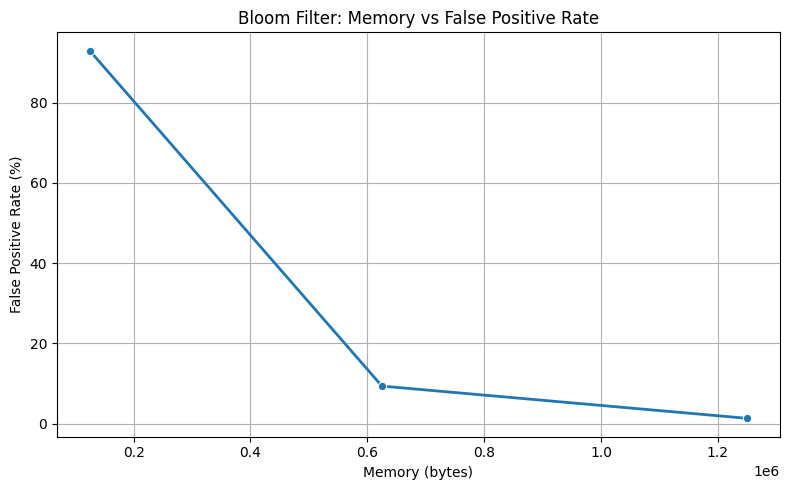

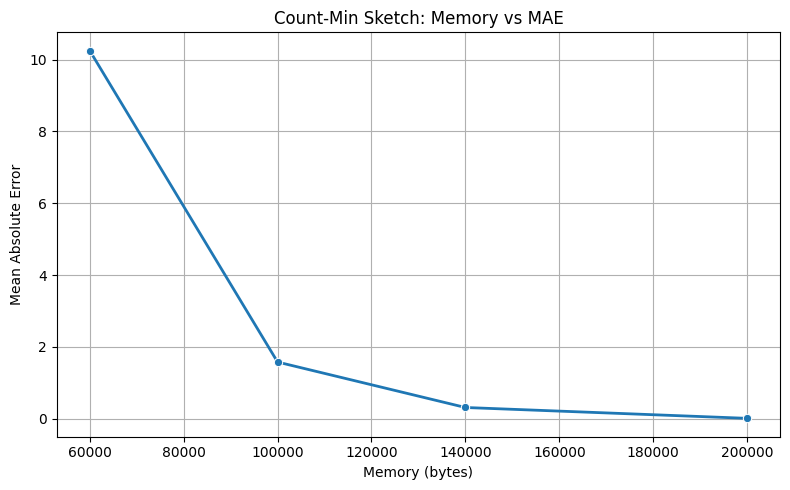

Final graphs and tables saved successfully!


In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=pd.DataFrame(controlled_bloom),
    x='Memory(bytes)',
    y='FPR(%)',
    marker='o',
    linewidth=2
)

plt.title('Bloom Filter: Memory vs False Positive Rate')
plt.xlabel('Memory (bytes)')
plt.ylabel('False Positive Rate (%)')
plt.grid(True)
plt.tight_layout()
plt.savefig('bloom_memory_fpr.png', dpi=300)
plt.show()

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=pd.DataFrame(controlled_cms),
    x='Memory(bytes)',
    y='MAE',
    marker='o',
    linewidth=2
)

plt.title('Count-Min Sketch: Memory vs MAE')
plt.xlabel('Memory (bytes)')
plt.ylabel('Mean Absolute Error')
plt.grid(True)
plt.tight_layout()
plt.savefig('cms_memory_mae.png', dpi=300)
plt.show()

pd.DataFrame(controlled_bloom).to_csv(
    'final_bloom_results.csv', index=False
)

pd.DataFrame(controlled_cms).to_csv(
    'final_cms_results.csv', index=False
)

print("Final graphs and tables saved successfully!")
